# Yambda 18 · Per-user new-artist weight

Notebook 17 used one new-artist weight `w` for everyone. On test, `w = 2` gave +19% new-artist recall
for −8% overall. Idea: push new artists only for users who already find new artists on their own.

**Signal.** `user_explore` = share of the user's discoveries in the last 60 days before the cutoff
(first play of a track, organic, played ≥ 50%) that were also their first play of that artist.
Shrunk toward the global share. Pre-cutoff data only.

**Method.** Two rankers from notebook 17: `w = 1` (best overall) and `w = 8` (best on new artists).
Per user, blend their within-user rank percentiles: `(1 − λ_u)·w1 + λ_u·w8`, with λ_u rising with the
user's exploration percentile. The average λ is `m`; λ_u runs from `m − d` to `m + d`, `d = min(m, 1 − m)`.

**Controls.**
1. Same blend, same `λ = m` for everyone. If per-user does not beat this, the gain is blending, not personalization.
2. `user_explore` as a plain ranker feature (with `w = 1` and `w = 2`).

**Decision rules, fixed before looking:**
- Personalization works if, for `m` = 0.25, 0.5 and 0.75, the per-user point has higher overall recall
  than the same-λ curve at the same new-artist recall (linear interpolation).
- If it works, pick the largest `m` whose overall recall stays within 5% of `w = 1` (as in notebook 17),
  compare it with global `w = 2`, then run test once.

Candidates are cached from notebook 17, so this runs in about 15 min.

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from musicrec import config
from musicrec.preprocess import Split
from musicrec.evaluation import evaluate, paired_bootstrap, artist_novelty
from musicrec.yambda import load_item_artist, build_events
from musicrec import ranking as R

pd.set_option("display.float_format", "{:,.4f}".format)
OUT = config.PROJECT_ROOT / "reports" / "yambda"
CACHE = config.YAMBDA_DIR / "cands"
S4 = ["ials", "sasrec", "pop", "bpr"]
FEATS = R.feature_columns(S4, organic=True)
FEATS_X = FEATS + ["user_explore"]
MS = [0.0, 0.25, 0.5, 0.75, 1.0]
item_artist = load_item_artist()
events = build_events(min_played_ratio=50)

In [2]:
def build(tag, split):
    """Same candidates and features as notebook 17 (step C), read from the cache, plus user_explore."""
    src = {s: pd.read_parquet(CACHE / f"{tag}_{s}.parquet") for s in S4}
    c = R.add_labels(R.merge_candidates(src), split)
    c = R.add_features(c, split, item_artist, S4)
    c = R.add_organic_features(c, split, events)
    c["rel"] = R.graded_relevance(c)
    explore = R.user_exploration(split, events, item_artist)
    c["user_explore"] = explore[c["user_idx"].to_numpy()]
    return c, explore

def evaluate_col(c, split, col, name, new_artist):
    m = R.PrecomputedScores(c[["user_idx", "item_idx", col]].dropna(), split.n_items, name, col)
    r = evaluate(m, split, return_per_user=True)
    rn = evaluate(m, split, targets=split.targets[new_artist], return_per_user=True)
    r["recall@10 | new-artist"], r["per_user_new"] = rn["recall@10"], rn["per_user"]
    r["recall@10 | known-artist"] = evaluate(m, split, targets=split.targets[~new_artist])["recall@10"]
    return r

def table(res):
    return pd.DataFrame({n: {k: v for k, v in r.items() if not k.startswith("per_user")} for n, r in res.items()}).T[
        ["recall@10", "recall@10 | known-artist", "recall@10 | new-artist", "hit_rate@10", "coverage@10"]]

## Candidates, features and the exploration signal

In [3]:
rank, val = Split.load(config.YAMBDA_SPLIT_RANK_DIR), Split.load(config.YAMBDA_SPLIT_VAL_DIR)
c_rank, _ = build("rank", rank)
c_val, explore_val = build("val", val)
new_artist_val = artist_novelty(val, item_artist)
users_val = np.unique(c_val["user_idx"])
print(f"user_explore on val users: mean {explore_val[users_val].mean():.3f}, "
      f"p10 {np.quantile(explore_val[users_val], .1):.3f}, p90 {np.quantile(explore_val[users_val], .9):.3f}")

user_explore on val users: mean 0.344, p10 0.184, p90 0.512


In [4]:
# Is the signal predictive? Share of each user's validation discoveries that are new-artist, by quintile of user_explore.
t = val.targets.assign(new=new_artist_val.to_numpy()).groupby("user_idx")["new"].mean()
q = pd.qcut(pd.Series(explore_val[t.index], index=t.index).rank(method="first"), 5, labels=["Q1 (low)", "Q2", "Q3", "Q4", "Q5 (high)"])
pd.DataFrame({"users": t.groupby(q, observed=True).size(),
              "user_explore": pd.Series(explore_val[t.index], index=t.index).groupby(q, observed=True).mean(),
              "new-artist share of val discoveries": t.groupby(q, observed=True).mean()})

,users,user_explore,new-artist share of val discoveries
Q1 (low),1136,0.1774,0.4557
Q2,1135,0.2754,0.5132
Q3,1136,0.3377,0.5844
Q4,1135,0.3980,0.5983
Q5 (high),1136,0.5315,0.6508


## Rankers (trained on the earlier window, scored on validation)

In [5]:
res = {}
for name, feats, gain in [("w=1", FEATS, None), ("w=2", FEATS, [0, 1, 2]), ("w=8", FEATS, [0, 1, 8]),
                          ("w=1 + explore feature", FEATS_X, None), ("w=2 + explore feature", FEATS_X, [0, 1, 2])]:
    t0 = time.time()
    m = R.fit_ranker(c_rank, feats) if gain is None else R.fit_ranker(c_rank, feats, label_col="rel", label_gain=gain)
    c_val[name] = m.predict(c_val[feats])
    res[name] = evaluate_col(c_val, val, name, name, new_artist_val)
    print(f"{name:<24} recall@10={res[name]['recall@10']:.4f}  new-artist={res[name]['recall@10 | new-artist']:.4f}  ({time.time() - t0:.0f}s)")

w=1                      recall@10=0.0524  new-artist=0.0186  (84s)
w=2                      recall@10=0.0532  new-artist=0.0244  (72s)
w=8                      recall@10=0.0498  new-artist=0.0346  (64s)
w=1 + explore feature    recall@10=0.0501  new-artist=0.0171  (54s)
w=2 + explore feature    recall@10=0.0516  new-artist=0.0233  (75s)


## Blends: same λ for everyone vs per-user λ

In [6]:
blend = {"same": {}, "per-user": {}}
for m in MS:
    for kind in blend:
        lam = np.full(val.n_users, m) if kind == "same" else R.spread_lambda(explore_val, users_val, m)
        col = f"{kind} m={m}"
        c_val[col] = R.per_user_blend(c_val, "w=1", "w=8", lam)
        blend[kind][m] = evaluate_col(c_val, val, col, col, new_artist_val)
        if kind == "same" and m in (0.0, 1.0):          # per-user equals same at the end points
            blend["per-user"][m] = blend["same"][m]
            break
tab = pd.concat([table(res), table({f"{k} λ, m={m}": r for k in blend for m, r in blend[k].items()})])
tab

,recall@10,recall@10 | known-artist,recall@10 | new-artist,hit_rate@10,coverage@10
w=1,0.0524,0.0674,0.0186,0.2319,0.0558
w=2,0.0532,0.0601,0.0244,0.2279,0.0521
w=8,0.0498,0.0427,0.0346,0.2212,0.0478
w=1 + explore feature,0.0501,0.0654,0.0171,0.2224,0.0572
w=2 + explore feature,0.0516,0.0598,0.0233,0.2295,0.0552
"same λ, m=0.0",0.0524,0.0674,0.0186,0.2319,0.0558
"same λ, m=0.25",0.0520,0.0596,0.0242,0.2307,0.0522
"same λ, m=0.5",0.0522,0.0549,0.0279,0.2281,0.0506
"same λ, m=0.75",0.0518,0.0499,0.0308,0.2268,0.0491
"same λ, m=1.0",0.0498,0.0427,0.0346,0.2212,0.0478


In [7]:
# Decision 1: does per-user beat the same-λ curve at equal new-artist recall?
xs = np.array([blend["same"][m]["recall@10 | new-artist"] for m in MS])
ys = np.array([blend["same"][m]["recall@10"] for m in MS])
order = np.argsort(xs)
check = pd.DataFrame({m: {"new-artist (per-user)": blend["per-user"][m]["recall@10 | new-artist"],
                          "overall (per-user)": blend["per-user"][m]["recall@10"],
                          "overall (same λ, interpolated)": np.interp(blend["per-user"][m]["recall@10 | new-artist"], xs[order], ys[order])}
                      for m in [0.25, 0.5, 0.75]}).T
check["gap"] = check["overall (per-user)"] - check["overall (same λ, interpolated)"]
PERSONALIZATION_WORKS = bool((check["gap"] > 0).all())
print("personalization works:", PERSONALIZATION_WORKS)
check

personalization works: False


,new-artist (per-user),overall (per-user),"overall (same λ, interpolated)",gap
0.2500,0.0252,0.0529,0.0521,0.0008
0.5000,0.0290,0.0517,0.0520,-0.0003
0.7500,0.0311,0.0512,0.0516,-0.0004


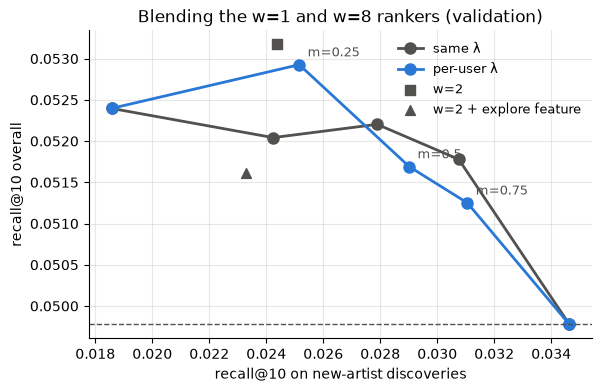

In [8]:
BLUE, GRAY = "#2a78d6", "#52514e"
fig, ax = plt.subplots(figsize=(6.5, 4))
for kind, color in [("same", GRAY), ("per-user", BLUE)]:
    px = [blend[kind][m]["recall@10 | new-artist"] for m in MS]
    py = [blend[kind][m]["recall@10"] for m in MS]
    ax.plot(px, py, color=color, lw=2, marker="o", markersize=8, label=f"{kind} λ")
for m in [0.25, 0.5, 0.75]:
    r = blend["per-user"][m]
    ax.annotate(f"m={m}", (r["recall@10 | new-artist"], r["recall@10"]), textcoords="offset points", xytext=(6, 6), color=GRAY, fontsize=9)
for name, mk in [("w=2", "s"), ("w=2 + explore feature", "^")]:
    r = res[name]
    ax.scatter([r["recall@10 | new-artist"]], [r["recall@10"]], color=GRAY, marker=mk, s=50, zorder=3, label=name)
ax.axhline(0.95 * res["w=1"]["recall@10"], color=GRAY, lw=1, ls="--")
ax.set(xlabel="recall@10 on new-artist discoveries", ylabel="recall@10 overall",
       title="Blending the w=1 and w=8 rankers (validation)")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
fig.savefig(config.YAMBDA_FIGURES_DIR / "y18_per_user_blend.png", dpi=150, bbox_inches="tight")

In [9]:
# Decision 2: the largest m within 5% of w=1 overall, then compare with global w=2
base = res["w=1"]["recall@10"]
M = max(m for m in MS if blend["per-user"][m]["recall@10"] >= 0.95 * base)
pick = blend["per-user"][M]
print(f"chosen m = {M}: overall {pick['recall@10']:.4f}, new-artist {pick['recall@10 | new-artist']:.4f}")
tab.to_csv(OUT / "ranker_per_user_val.csv")
pd.DataFrame({
    f"per-user m={M} vs w=2, overall":    paired_bootstrap(res["w=2"]["per_user"], pick["per_user"]),
    f"per-user m={M} vs w=2, new-artist": paired_bootstrap(res["w=2"]["per_user_new"], pick["per_user_new"]),
    f"per-user m={M} vs w=1, overall":    paired_bootstrap(res["w=1"]["per_user"], pick["per_user"]),
}).T[["a", "b", "diff", "rel_diff", "ci_low", "ci_high", "p(b<=a)"]]

chosen m = 0.75: overall 0.0512, new-artist 0.0311


,a,b,diff,rel_diff,ci_low,ci_high,p(b<=a)
"per-user m=0.75 vs w=2, overall",0.0532,0.0512,-0.0019,-0.0361,-0.0041,0.0002,0.9605
"per-user m=0.75 vs w=2, new-artist",0.0244,0.0311,0.0067,0.2733,0.0047,0.0087,0.0000
"per-user m=0.75 vs w=1, overall",0.0524,0.0512,-0.0011,-0.0219,-0.0035,0.0012,0.8400


## Test (run once, after we agree on the validation result)

Rankers retrained on the validation window (as in notebook 17), exploration recomputed with test's cutoff,
blend with the `m` chosen above. Compared with `w = 1` and `w = 2`.

In [10]:
RUN_TEST = False
if RUN_TEST:
    test = Split.load(config.YAMBDA_SPLIT_TEST_DIR)
    c_test, explore_test = build("test", test)
    na_test = artist_novelty(test, item_artist)
    users_test = np.unique(c_test["user_idx"])
    for name, gain in [("w=1", None), ("w=2", [0, 1, 2]), ("w=8", [0, 1, 8])]:
        m = R.fit_ranker(c_val, FEATS) if gain is None else R.fit_ranker(c_val, FEATS, label_col="rel", label_gain=gain)
        c_test[name] = m.predict(c_test[FEATS])
    c_test["per-user"] = R.per_user_blend(c_test, "w=1", "w=8", R.spread_lambda(explore_test, users_test, M))
    c_test["same"] = R.per_user_blend(c_test, "w=1", "w=8", np.full(test.n_users, M))
    res_t = {n: evaluate_col(c_test, test, n, n, na_test) for n in ["w=1", "w=2", "same", "per-user"]}
    res_t = {"w=1": res_t["w=1"], "w=2": res_t["w=2"], f"same λ, m={M}": res_t["same"], f"per-user λ, m={M}": res_t["per-user"]}
    names = list(res_t)
    sig_t = pd.DataFrame({
        f"{names[3]} vs w=2, overall":    paired_bootstrap(res_t["w=2"]["per_user"], res_t[names[3]]["per_user"]),
        f"{names[3]} vs w=2, new-artist": paired_bootstrap(res_t["w=2"]["per_user_new"], res_t[names[3]]["per_user_new"]),
        f"{names[3]} vs {names[2]}, overall": paired_bootstrap(res_t[names[2]]["per_user"], res_t[names[3]]["per_user"]),
        f"{names[3]} vs w=1, overall":    paired_bootstrap(res_t["w=1"]["per_user"], res_t[names[3]]["per_user"]),
    }).T
    table(res_t).to_csv(OUT / "final_test_per_user.csv"); sig_t.to_csv(OUT / "final_test_per_user_significance.csv")
    display(table(res_t), sig_t[["a", "b", "diff", "rel_diff", "ci_low", "ci_high", "p(b<=a)"]])